# Challenge 2 — Steps 3–4: Logistic Regression, Naïve Bayes, KNN, SVM

Owner: Joaquin De La Barrera. This notebook covers the four linear/probabilistic/distance-based required models:

1. **Step 3:** baseline 5-fold CV results for Logistic Regression, Gaussian Naïve Bayes, KNN and SVM
2. **Step 4:** Grid Search for these models

Team conventions (from `AGENTS.md`):
- `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`
- `scoring="f1"`, i.e. F1 for `Revenue=True`
- preprocessing and model in one `Pipeline`
- the test file is **not** loaded here

> Daniel's Step 1–2 helper is not merged yet, so this notebook defines a preprocessor that follows the column groups proposed in `AGENTS.md`. When the shared helper is in `main`, swap `make_preprocessor` for it so all results are comparable.

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)  # liblinear `penalty` deprecation notice in sklearn >= 1.8
pd.set_option("display.float_format", "{:.4f}".format)

RANDOM_STATE = 42
DATA = Path("Data")

train = pd.read_csv(DATA / "challenge2_train.csv")       # only the training file is used
X = train.drop(columns=["ID", "Revenue"])                 # ID is never a feature
y = train["Revenue"].astype(int)                          # 1 = purchase
print(X.shape, f"positive rate = {y.mean():.2%}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = "f1"

(9247, 17) positive rate = 15.48%


## Preprocessing

These four models need scaled inputs. KNN and SVM rely on distances or margins, Logistic Regression's regularization is scale-sensitive, and Gaussian NB assumes each feature is roughly normal within a class.

- **Numeric** (counts, durations, rates, `PageValues`, `SpecialDay`) → `StandardScaler`
- **Categorical** (`Month`, `VisitorType`, `Weekend`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`) → `OneHotEncoder`. The last four are numbered categories, not amounts. Levels with fewer than 30 rows are grouped as "infrequent", and unseen levels are ignored.

Counts, durations and `PageValues` are very right-skewed, so we also try an optional `log1p` on those columns before scaling and compare both versions below.

In [2]:
SKEWED = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
          "ProductRelated", "ProductRelated_Duration", "PageValues"]
RATES = ["BounceRates", "ExitRates", "SpecialDay"]
CATEGORICAL = ["Month", "VisitorType", "Weekend", "OperatingSystems", "Browser", "Region", "TrafficType"]
X[CATEGORICAL] = X[CATEGORICAL].astype(str)

print("Skewness of the skewed group:")
print(X[SKEWED].skew().round(1).to_string())


def make_preprocessor(log_skewed: bool = True) -> ColumnTransformer:
    skewed_steps = ([("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one"))] if log_skewed else [])
    skewed_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("skewed", Pipeline(skewed_steps), SKEWED),
        ("rates", StandardScaler(), RATES),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False), CATEGORICAL),
    ])


def make_pipeline(model, log_skewed: bool = True) -> Pipeline:
    return Pipeline([("prep", make_preprocessor(log_skewed)), ("model", model)])


def evaluate(name, pipe):
    r = cross_validate(pipe, X, y, cv=cv, scoring=["f1", "precision", "recall", "roc_auc", "average_precision"],
                       return_train_score=True, n_jobs=-1)
    return {"Model": name,
            "Train F1": r["train_f1"].mean(),
            "CV F1": r["test_f1"].mean(), "CV F1 std": r["test_f1"].std(),
            "Gap (train-CV)": r["train_f1"].mean() - r["test_f1"].mean(),
            "Precision": r["test_precision"].mean(), "Recall": r["test_recall"].mean(),
            "ROC-AUC": r["test_roc_auc"].mean(), "PR-AUC": r["test_average_precision"].mean(),
            "Fit time (s)": r["fit_time"].mean()}

Skewness of the skewed group:
Administrative            2.0000
Administrative_Duration   5.7000
Informational             4.2000
Informational_Duration    7.8000
ProductRelated            4.4000
ProductRelated_Duration   8.2000
PageValues                6.3000


## Step 3 — Baseline models (default hyperparameters)

`DummyClassifier(strategy="stratified")` makes random guesses at the 15% base rate. Every model has to beat it.

In [3]:
MODELS = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    "Naive Bayes": GaussianNB(),
    "KNN": KNeighborsClassifier(),
    "SVM (RBF)": SVC(random_state=RANDOM_STATE),
}

rows = [evaluate("Dummy (stratified)", make_pipeline(DummyClassifier(strategy="stratified", random_state=RANDOM_STATE)))]
rows[0]["Preprocessing"] = "-"
for log_skewed in [False, True]:
    for name, model in MODELS.items():
        t0 = time.time()
        row = evaluate(name, make_pipeline(model, log_skewed))
        row["Preprocessing"] = "log1p + scale" if log_skewed else "scale only"
        rows.append(row)
        print(f"{name:20s} {row['Preprocessing']:14s} CV F1 = {row['CV F1']:.4f}  ({time.time() - t0:.1f}s)")

baseline = pd.DataFrame(rows)
cols = ["Model", "Preprocessing", "Train F1", "CV F1", "CV F1 std", "Gap (train-CV)", "Precision", "Recall",
        "ROC-AUC", "PR-AUC", "Fit time (s)"]
display(baseline[cols])

Logistic Regression  scale only     CV F1 = 0.5158  (2.9s)
Naive Bayes          scale only     CV F1 = 0.4243  (2.8s)
KNN                  scale only     CV F1 = 0.4929  (3.2s)
SVM (RBF)            scale only     CV F1 = 0.5984  (4.3s)
Logistic Regression  log1p + scale  CV F1 = 0.6333  (0.2s)
Naive Bayes          log1p + scale  CV F1 = 0.4318  (0.2s)
KNN                  log1p + scale  CV F1 = 0.6071  (1.1s)
SVM (RBF)            log1p + scale  CV F1 = 0.6499  (3.5s)


,Model,Preprocessing,Train F1,CV F1,CV F1 std,Gap (train-CV),Precision,Recall,ROC-AUC,PR-AUC,Fit time (s)
0,Dummy (stratified),-,0.1568,0.1406,0.0153,0.0162,0.1388,0.1426,0.4903,0.1527,0.0920
1,Logistic Regression,scale only,0.5236,0.5158,0.0283,0.0079,0.7511,0.3941,0.8957,0.6529,0.1556
2,Naive Bayes,scale only,0.4326,0.4243,0.0129,0.0083,0.2901,0.7910,0.7930,0.4296,0.0939
3,KNN,scale only,0.6044,0.4929,0.0140,0.1116,0.6793,0.3878,0.7972,0.4948,0.0671
4,SVM (RBF),scale only,0.6644,0.5984,0.0185,0.0660,0.7517,0.4982,0.8809,0.6959,1.0235
5,Logistic Regression,log1p + scale,0.6375,0.6333,0.0175,0.0043,0.7053,0.5751,0.9162,0.6950,0.1038
6,Naive Bayes,log1p + scale,0.4368,0.4318,0.0101,0.0050,0.2877,0.8665,0.8213,0.4361,0.0616
7,KNN,log1p + scale,0.7187,0.6071,0.0271,0.1116,0.6682,0.5569,0.8651,0.5978,0.0611
8,SVM (RBF),log1p + scale,0.7074,0.6499,0.0253,0.0575,0.7228,0.5912,0.8937,0.7239,0.6783


In [4]:
pivot = baseline[baseline["Model"] != "Dummy (stratified)"].pivot(index="Model", columns="Preprocessing", values="CV F1")
pivot["Δ (log1p − scale only)"] = pivot["log1p + scale"] - pivot["scale only"]
display(pivot)

Preprocessing,log1p + scale,scale only,Δ (log1p − scale only)
Model,,,
KNN,0.6071,0.4929,0.1142
Logistic Regression,0.6333,0.5158,0.1175
Naive Bayes,0.4318,0.4243,0.0075
SVM (RBF),0.6499,0.5984,0.0515


**Baseline observations**

- The **log1p transform** of the skewed columns improves every model. The gains are large for Logistic Regression and KNN (about +0.12 F1 each) and for SVM (about +0.05). Long-tailed counts and durations distort the linear decision boundary and the distances. We keep `log1p + scale` for the Grid Search.
- **Logistic Regression** and **SVM** reach a good ROC-AUC, but at the default threshold they favour the majority class: precision is higher than recall. That is why `class_weight="balanced"` goes into their grids.
- **Naïve Bayes** has the opposite pattern (high recall, low precision), and log1p barely helps it. Its independence assumption fails on strongly correlated pairs such as page counts vs durations and `BounceRates` vs `ExitRates`, which counts the same evidence several times.
- Logistic Regression and Naïve Bayes have almost no train−CV gap, so their errors are bias (underfitting / model assumptions), not overfitting. Default KNN (*k*=5) shows the largest gap (about 0.11), a sign of variance, and SVM has a moderate one.

## Step 4 — Grid Search (5-fold stratified CV, `scoring="f1"`)

The grids target the main issues in the baseline:
- **Logistic Regression:** regularization strength `C`, L1 vs L2, `class_weight`
- **SVM (RBF):** `C`, `gamma`, `class_weight`
- **KNN:** number of neighbours, uniform vs distance weighting, Manhattan vs Euclidean distance
- **Naïve Bayes:** `var_smoothing` (its only hyperparameter, so the grid is quick)

In [5]:
GRIDS = {
    "Logistic Regression": (LogisticRegression(max_iter=5000, solver="liblinear", random_state=RANDOM_STATE),
        {"model__C": [0.001, 0.003, 0.01, 0.03, 0.1, 1, 10], "model__penalty": ["l1", "l2"], "model__class_weight": [None, "balanced"]}),
    "SVM (RBF)": (SVC(kernel="rbf", random_state=RANDOM_STATE),
        {"model__C": [0.03, 0.1, 0.3, 1, 3], "model__gamma": [0.001, 0.003, 0.01, 0.03, "scale"], "model__class_weight": [None, "balanced"]}),
    "KNN": (KNeighborsClassifier(),
        {"model__n_neighbors": [3, 5, 11, 21, 31, 51], "model__weights": ["uniform", "distance"], "model__p": [1, 2]}),
    "Naive Bayes": (GaussianNB(),
        {"model__var_smoothing": np.logspace(-11, 1, 13)}),
}

searches, tuned_rows = {}, []
for name, (model, grid) in GRIDS.items():
    t0 = time.time()
    gs = GridSearchCV(make_pipeline(model, log_skewed=True), grid, cv=cv, n_jobs=-1, return_train_score=True,
                      scoring={"f1": "f1", "precision": "precision", "recall": "recall"}, refit="f1")
    gs.fit(X, y)
    searches[name] = gs
    i, r = gs.best_index_, gs.cv_results_
    tuned_rows.append({"Model": name, "Train F1": r["mean_train_f1"][i], "CV F1": r["mean_test_f1"][i],
                       "CV F1 std": r["std_test_f1"][i], "Gap (train-CV)": r["mean_train_f1"][i] - r["mean_test_f1"][i],
                       "Precision": r["mean_test_precision"][i], "Recall": r["mean_test_recall"][i],
                       "Combos": len(r["params"]), "Search time (s)": round(time.time() - t0),
                       "Best params": {k.replace("model__", ""): v for k, v in gs.best_params_.items()}})
    print(f"{name:20s} best CV F1 = {gs.best_score_:.4f}  {tuned_rows[-1]['Best params']}  ({time.time() - t0:.0f}s)")

tuned = pd.DataFrame(tuned_rows).sort_values("CV F1", ascending=False).reset_index(drop=True)

Logistic Regression  best CV F1 = 0.6796  {'C': 0.03, 'class_weight': 'balanced', 'penalty': 'l1'}  (3s)
SVM (RBF)            best CV F1 = 0.6773  {'C': 1, 'class_weight': 'balanced', 'gamma': 0.003}  (324s)
KNN                  best CV F1 = 0.6335  {'n_neighbors': 31, 'p': 2, 'weights': 'uniform'}  (117s)
Naive Bayes          best CV F1 = 0.6003  {'var_smoothing': np.float64(1.0)}  (7s)


In [6]:
base_log = baseline[baseline["Preprocessing"] == "log1p + scale"].set_index("Model")["CV F1"]
summary = tuned.set_index("Model")
summary.insert(0, "Baseline CV F1", base_log)
summary.insert(2, "Δ from tuning", summary["CV F1"] - summary["Baseline CV F1"])
pd.set_option("display.max_colwidth", 120)
display(summary)

Path("results").mkdir(exist_ok=True)
summary.reset_index().to_csv("results/step3_4_linear_models.csv", index=False)

,Baseline CV F1,Train F1,Δ from tuning,CV F1,CV F1 std,Gap (train-CV),Precision,Recall,Combos,Search time (s),Best params
Model,,,,,,,,,,,
Logistic Regression,0.6333,0.6791,0.0464,0.6796,0.0087,-0.0005,0.5910,0.8001,28,3,"{'C': 0.03, 'class_weight': 'balanced', 'penalty': 'l1'}"
SVM (RBF),0.6499,0.6780,0.0274,0.6773,0.0096,0.0007,0.5887,0.7980,50,324,"{'C': 1, 'class_weight': 'balanced', 'gamma': 0.003}"
KNN,0.6071,0.6470,0.0264,0.6335,0.0218,0.0135,0.7257,0.5625,24,117,"{'n_neighbors': 31, 'p': 2, 'weights': 'uniform'}"
Naive Bayes,0.4318,0.6016,0.1685,0.6003,0.0105,0.0013,0.5181,0.7142,13,7,{'var_smoothing': 1.0}


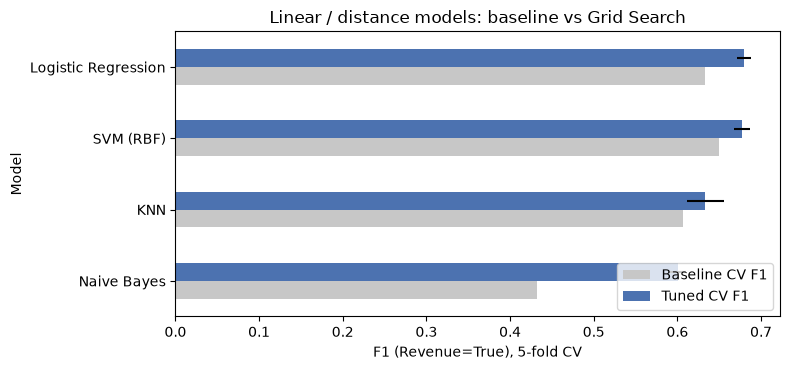

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
plot_df = summary[["Baseline CV F1", "CV F1"]].rename(columns={"CV F1": "Tuned CV F1"}).sort_values("Tuned CV F1")
plot_df.plot.barh(ax=ax, color=["#C7C7C7", "#4C72B0"], xerr={"Tuned CV F1": summary.loc[plot_df.index, "CV F1 std"]})
ax.set_xlabel("F1 (Revenue=True), 5-fold CV"); ax.set_title("Linear / distance models: baseline vs Grid Search")
plt.tight_layout(); plt.show()

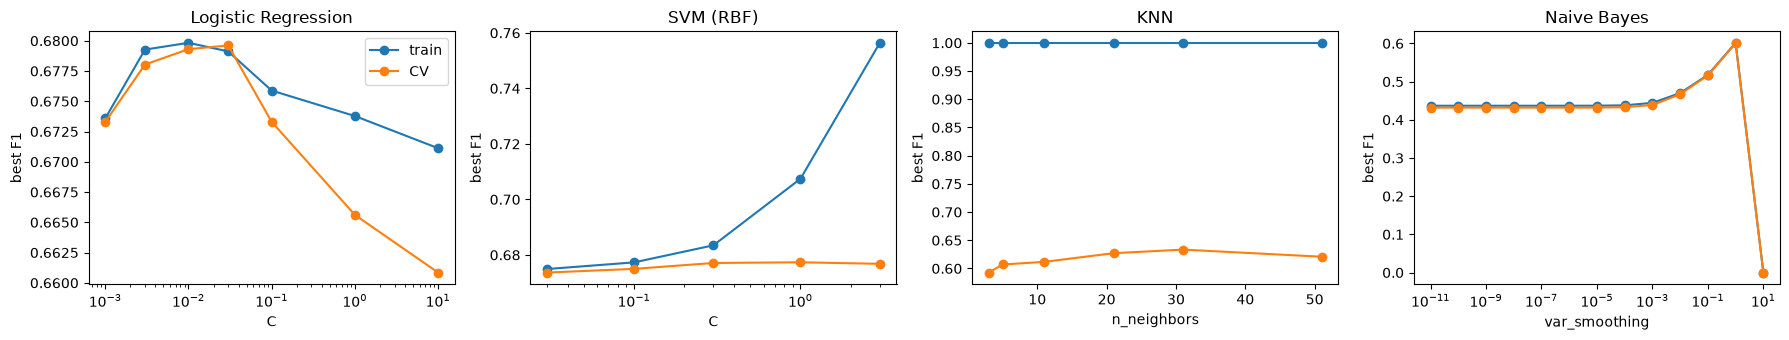

In [8]:
# How sensitive is each model to its main hyperparameter? (mean CV F1 across the rest of the grid)
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, (name, param) in zip(axes, [("Logistic Regression", "model__C"), ("SVM (RBF)", "model__C"),
                                    ("KNN", "model__n_neighbors"), ("Naive Bayes", "model__var_smoothing")]):
    res = pd.DataFrame(searches[name].cv_results_)
    g = res.groupby(res["param_" + param].astype(float))[["mean_train_f1", "mean_test_f1"]].max()
    g.plot(ax=ax, marker="o", logx=param != "model__n_neighbors", legend=False)
    ax.set_title(name); ax.set_xlabel(param.replace("model__", "")); ax.set_ylabel("best F1")
axes[0].legend(["train", "CV"])
plt.tight_layout(); plt.show()

## Takeaways for Steps 5–6

- The tuned table above is this group's entry for the team comparison table in `AGENTS.md`.
- For **Logistic Regression and SVM**, the best grids both use `class_weight="balanced"`. Most of the gain comes from trading precision for recall: recall rises from about 0.58 to about 0.80. Tuning the decision threshold directly (Person 4's optional task) targets the same issue and should help the tree models as well.
- **Naïve Bayes** gains the most from tuning. Heavy `var_smoothing` widens every class-conditional Gaussian, which partly offsets the double-counting of correlated features. It is still the weakest model in this group.
- **KNN** prefers a large *k* (31). Small *k* overfits (train F1 well above CV F1 in the validation curve), and KNN keeps the largest train−CV gap of the four.
- **Logistic Regression** ties SVM for the best F1 in this group. It has the lowest fold-to-fold variance, trains in milliseconds rather than minutes, and its coefficients are interpretable, so it's the pick from this group and a strong fallback if the tree models only win by a small margin.